In [ ]:
#is lsb

In [8]:
import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, log_loss, f1_score

# ground truth
test_df = load_dataset("mwalmsley/is-lsb")['test'].to_pandas()[['id_str', 'label']]


root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
all_folders = sorted(
    [f for f in glob.glob(f"{root}/*is-lsb*")
     if os.path.exists(os.path.join(f, "predictions_test.csv"))
     and os.path.exists(os.path.join(f, "checkpoints"))],
    key=os.path.getmtime, reverse=True
)
folders = all_folders[:6]   # the 6 newest 


for f in folders:
    print("  ", os.path.basename(f))
print()

rows = []
for f in folders:
    pred = pd.read_csv(os.path.join(f, "predictions_test.csv"))
    m = pred.merge(test_df, on='id_str', how='inner')
    prob = m['class_1'].values
    true = m['label'].values
    pclass = (prob >= 0.5).astype(int)
    seed = os.path.basename(f).split('_')[-3]
    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, prob),
        'balanced_acc': balanced_accuracy_score(true, pclass),
        'f1': f1_score(true, pclass),
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\nTest loss:    {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}   (paper 0.0713)")
print(f"Balanced acc: {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")

   local_is-lsb_5_2026-06-27_12-53-32
   local_is-lsb_4_2026-06-27_12-44-42
   local_is-lsb_3_2026-06-27_12-35-47
   local_is-lsb_2_2026-06-27_12-25-19
   local_is-lsb_1_2026-06-27_12-11-14
   local_is-lsb_0_2026-06-27_11-56-57

seed  test_loss  balanced_acc       f1  n_matched
   5   0.081980      0.966472 0.949640        863
   4   0.076468      0.966345 0.951175        863
   3   0.076428      0.967067 0.954463        863
   2   0.074739      0.963544 0.949091        863
   1   0.074611      0.969018 0.954792        863
   0   0.080059      0.972541 0.960145        863

Test loss:    0.0774 ± 0.0030   (paper 0.0713)
Balanced acc: 0.9675 ± 0.0030


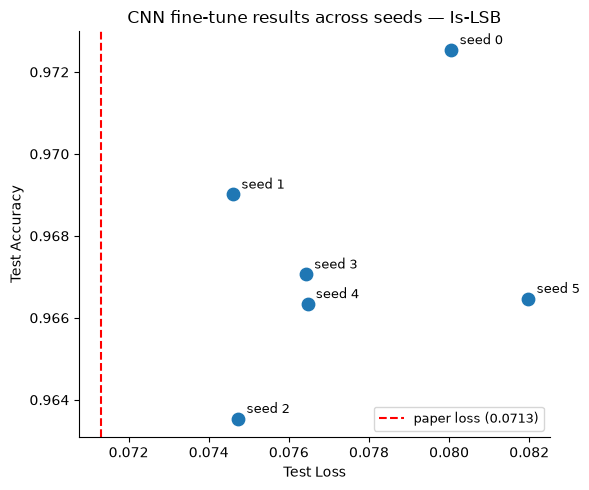

In [10]:
import matplotlib.pyplot as plt

seeds  = [5,        4,        3,        2,        1,        0       ]
loss   = [0.081980, 0.076468, 0.076428, 0.074739, 0.074611, 0.080059]
acc    = [0.966472, 0.966345, 0.967067, 0.963544, 0.969018, 0.972541]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(loss, acc, s=80, zorder=3)

for s, x, y in zip(seeds, loss, acc):
    ax.annotate(f"seed {s}", (x, y), textcoords="offset points", xytext=(6, 4), fontsize=9)

ax.axvline(0.0713, color="red", linestyle="--", linewidth=1.5, label="paper loss (0.0713)")

ax.set_xlabel("Test Loss")
ax.set_ylabel("Test Accuracy")
ax.set_title("CNN fine-tune results across seeds — Is-LSB")
ax.legend(fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("seeds_plot_islsb.png", dpi=150)
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, log_loss, f1_score

# ===== change this line only: 2, 4, or 10 =====
DIVISOR = 2
# ==============================================
pct = {2: "50%", 4: "25%", 10: "10%"}.get(DIVISOR, f"1/{DIVISOR}")

test_df = load_dataset("mwalmsley/is-lsb")['test'].to_pandas()[['id_str', 'label']]

root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
folders = sorted([
    f for f in glob.glob(f"{root}/*is-lsb_div{DIVISOR}_*")
    if os.path.exists(os.path.join(f, "predictions_test.csv"))
    and os.path.exists(os.path.join(f, "checkpoints"))
])

print(f"is-lsb {pct} ")
for f in folders:
    print("  ", os.path.basename(f))
print()

rows = []
for f in folders:
    pred = pd.read_csv(os.path.join(f, "predictions_test.csv"))
    m = pred.merge(test_df, on='id_str', how='inner')
    prob = m['class_1'].values
    true = m['label'].values
    pclass = (prob >= 0.5).astype(int)
    seed = os.path.basename(f).split('_')[-3]
    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, prob),
        'balanced_acc': balanced_accuracy_score(true, pclass),
        'f1': f1_score(true, pclass, zero_division=0),
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\n=== is-lsb {pct} data (div{DIVISOR}) ===")
print(f"Test loss:    {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}")
print(f"Balanced acc: {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")


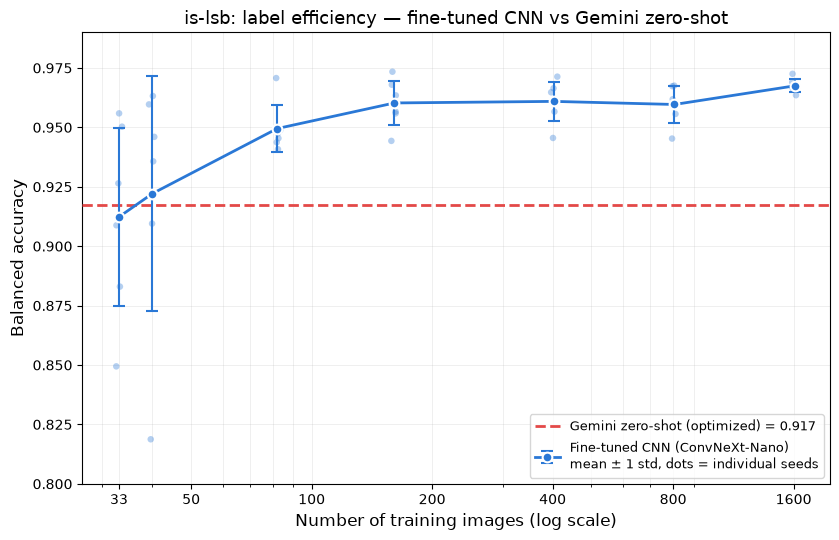

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# Per-seed balanced accuracy, keyed by number of training images
# (n_images computed as 1612 / divisor; 82 and 40 confirmed from logs)
runs = {
    1612: [0.972541, 0.969018, 0.963544, 0.967067, 0.966345, 0.966472],   # 100% (div1)
    806:  [0.967321, 0.945296, 0.955650, 0.961846, 0.967575, 0.960148],   # div2
    403:  [0.960870, 0.945550, 0.956626, 0.966472, 0.971351, 0.964774],   # div4
    161:  [0.963457, 0.944320, 0.956626, 0.955904, 0.973430, 0.967956],   # div10
    82:   [0.947502, 0.940797, 0.948818, 0.945423, 0.970756, 0.943725],   # div20
    40:   [0.818748, 0.946018, 0.909521, 0.963203, 0.959681, 0.935704],   # div40
    33:   [0.849429, 0.882998, 0.908799, 0.950302, 0.955904, 0.926453],   # div50
}
gemini = 0.9173  # optimized zero-shot baseline

xs        = sorted(runs.keys())
means     = [np.mean(runs[x]) for x in xs]
stds      = [np.std(runs[x])  for x in xs]

fig, ax = plt.subplots(figsize=(8.5, 5.5))

# individual seed points (faint, jittered slightly for visibility)
for x in xs:
    seeds = runs[x]
    jitter = x * np.random.uniform(-0.02, 0.02, size=len(seeds))  # tiny horizontal spread
    ax.scatter(np.full(len(seeds), x) + jitter, seeds,
               s=22, color='#2a78d6', alpha=0.35, zorder=2, edgecolors='none')

# mean line with error bars
ax.errorbar(xs, means, yerr=stds, fmt='o-', color='#2a78d6',
            ecolor='#2a78d6', elinewidth=1.5, capsize=4,
            markersize=7, markerfacecolor='#2a78d6',
            markeredgecolor='white', markeredgewidth=1.5,
            linewidth=2, label='Fine-tuned CNN (ConvNeXt-Nano)\nmean ± 1 std, dots = individual seeds',
            zorder=4)

# Gemini baseline
ax.axhline(gemini, color='#e34948', linestyle='--', linewidth=2,
           label=f'Gemini zero-shot (optimized) = {gemini:.3f}', zorder=3)

ax.set_xscale('log')
ax.set_xlabel('Number of training images (log scale)', fontsize=12)
ax.set_ylabel('Balanced accuracy', fontsize=12)
ax.set_title('is-lsb: label efficiency — fine-tuned CNN vs Gemini zero-shot', fontsize=13)

ax.set_xticks([33, 50, 100, 200, 400, 800, 1600])
ax.get_xaxis().set_major_formatter(mticker.ScalarFormatter())
ax.set_ylim(0.80, 0.99)

ax.grid(True, which='both', linestyle='-', linewidth=0.4, alpha=0.35)
ax.legend(loc='lower right', fontsize=9, frameon=True)



plt.tight_layout()
plt.savefig('is_lsb_label_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

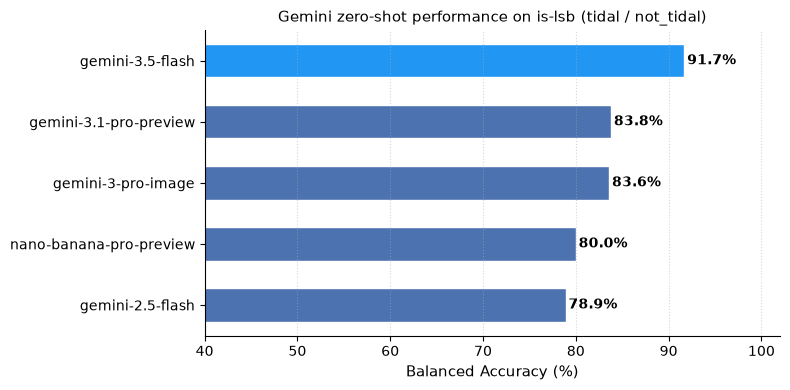

In [3]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "gemini-2.5-flash",
    "nano-banana-pro-preview",
    "gemini-3-pro-image",
    "gemini-3.1-pro-preview",
    "gemini-3.5-flash",
]
bal_acc = [78.9, 80.0, 83.6, 83.8, 91.7]

fig, ax = plt.subplots(figsize=(8, 4))

colors = ["#4C72B0" if v < 90 else "#2196F3" for v in bal_acc]
bars = ax.barh(models, bal_acc, color=colors, height=0.55, edgecolor="white")

for bar, val in zip(bars, bal_acc):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", ha="left", fontsize=10, fontweight="bold")



ax.set_xlabel("Balanced Accuracy (%)", fontsize=11)
ax.set_title("Gemini zero-shot performance on is-lsb (tidal / not_tidal)", fontsize=11)
ax.set_xlim(40, 102)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("is_lsb_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
#rings

In [9]:
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("/geir_data/scr/reem/gz_evo_results/dnb_debug/predict_gz_rings_0/rings_test_preds.csv")
print(f"rows: {len(df)}")
print(df.head())
print(f"pred range: {df['pred'].min():.3f} to {df['pred'].max():.3f}")
print(f"true range: {df['true'].min():.3f} to {df['true'].max():.3f}")

# binarize at 0.5 (ring / not-ring)
pred_bin = (df["pred"] >= 0.5).astype(int)
true_bin = (df["true"] >= 0.5).astype(int)

print(f"\nBalanced accuracy: {balanced_accuracy_score(true_bin, pred_bin):.4f}")
print(f"positives — true: {true_bin.sum()}, predicted: {pred_bin.sum()}")
print("\nConfusion matrix [rows=true, cols=pred]:")
print(confusion_matrix(true_bin, pred_bin))
print(classification_report(true_bin, pred_bin, target_names=['no ring','ring'], zero_division=0))

rows: 18340
       pred      true
0  0.240757  0.500000
1  0.594334  0.727273
2  0.749104  1.000000
3  0.169377  0.300000
4  0.456992  0.800000
pred range: -0.020 to 0.917
true range: 0.000 to 1.000

Balanced accuracy: 0.8627
positives — true: 9344, predicted: 8699

Confusion matrix [rows=true, cols=pred]:
[[8054  942]
 [1587 7757]]
              precision    recall  f1-score   support

     no ring       0.84      0.90      0.86      8996
        ring       0.89      0.83      0.86      9344

    accuracy                           0.86     18340
   macro avg       0.86      0.86      0.86     18340
weighted avg       0.86      0.86      0.86     18340



In [1]:
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

# use the path from the "Saved ... to" log line
df = pd.read_csv("/geir_data/scr/reem/gz_evo_results/dnb_debug/predict_gz_rings_0/rings_test_preds.csv")
pred_bin = (df["pred"] >= 0.5).astype(int)
true_bin = (df["true"] >= 0.5).astype(int)
print(f"Balanced accuracy: {balanced_accuracy_score(true_bin, pred_bin):.4f}")
print(f"(full-data rings was 0.8627)")
print(confusion_matrix(true_bin, pred_bin))

Balanced accuracy: 0.8579
(full-data rings was 0.8627)
[[8057  939]
 [1681 7663]]


In [2]:
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

for DIV in [4, 20]:
    path = f"/geir_data/scr/reem/gz_evo_results/dnb_debug/predict_gz_rings_div{DIV}_0/rings_test_preds.csv"
    df = pd.read_csv(path)
    pb = (df["pred"] >= 0.5).astype(int)
    tb = (df["true"] >= 0.5).astype(int)
    print(f"rings div{DIV} ({'25%' if DIV==4 else '5%'}): bal acc = {balanced_accuracy_score(tb, pb):.4f}")
    print(confusion_matrix(tb, pb))

rings div4 (25%): bal acc = 0.8584
[[8065  931]
 [1679 7665]]
rings div20 (5%): bal acc = 0.8545
[[8019  977]
 [1704 7640]]


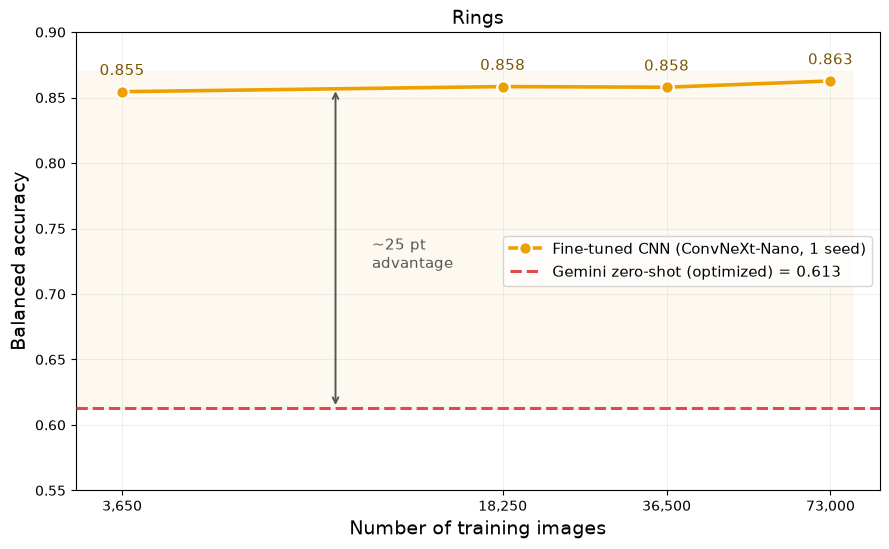

In [4]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# rings label-efficiency: (n_images, balanced_acc) - single seed each
data = [
    (73000, 0.8627),   # 100%
    (36500, 0.8579),   # 50% (div2)
    (18250, 0.8584),   # 25% (div4)
    (3650,  0.8545),   # 5%  (div20)
]
gemini = 0.613

n_imgs = [d[0] for d in data]
acc    = [d[1] for d in data]

fig, ax = plt.subplots(figsize=(9, 5.6))

# CNN line
ax.plot(n_imgs, acc, 'o-', color='#eda100', markersize=9, linewidth=2.6,
        markerfacecolor='#eda100', markeredgecolor='white', markeredgewidth=1.6,
        label='Fine-tuned CNN (ConvNeXt-Nano, 1 seed)', zorder=4)

# annotate each point value
for x, y in data:
    ax.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 12),
                ha='center', fontsize=11, color='#7a5300')

# Gemini baseline
ax.axhline(gemini, color='#e34948', linestyle='--', linewidth=2.2,
           label=f'Gemini zero-shot (optimized) = {gemini:.3f}', zorder=3)

# shade the CNN's advantage
ax.fill_between([3000, 80000], gemini, 0.87, color='#eda100', alpha=0.06, zorder=1)

ax.set_xscale('log')
ax.set_xlabel('Number of training images', fontsize=14)
ax.set_ylabel('Balanced accuracy', fontsize=14)
ax.set_title('Rings', fontsize=14)

ax.set_xticks([3650, 18250, 36500, 73000])
ax.set_xticklabels(['3,650', '18,250', '36,500', '73,000'])
ax.minorticks_off()
ax.set_xlim(3000, 90000)
ax.set_ylim(0.55, 0.90)

ax.grid(True, which='major', linestyle='-', linewidth=0.4, alpha=0.35)
ax.legend(loc='center right', fontsize=11)

# annotate the gap
ax.annotate('', xy=(9000, 0.857), xytext=(9000, 0.613),
            arrowprops=dict(arrowstyle='<->', color='#555', lw=1.4))
ax.text(10500, 0.73, '~25 pt\nadvantage', fontsize=11, color='#555', va='center')

plt.tight_layout()
plt.savefig('rings_label_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
#which_lsb

In [6]:
from datasets import load_dataset
ds = load_dataset("mwalmsley/which-lsb")
print(ds['test'].features)          # shows the label feature + class order
print(ds['test'].to_pandas()['label'].value_counts())  # class distribution

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['arm', 'stream', 'shell', 'diffuse']), 'id_str': Value('string')}
label
3    96
0    73
1    43
2     6
Name: count, dtype: int64


In [1]:
import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report, log_loss

# ground truth — class order confirmed: 0=arm, 1=stream, 2=shell, 3=diffuse
class_names = ['arm', 'stream', 'shell', 'diffuse']
prob_cols   = ['class_0', 'class_1', 'class_2', 'class_3']

test_df = load_dataset("mwalmsley/which-lsb")['test'].to_pandas()[['id_str', 'label']]

# find the 6 which-lsb seed folders (only completed ones, with predictions)
root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
folders = sorted(glob.glob(f"{root}/*which-lsb*"))
folders = [f for f in folders if os.path.exists(os.path.join(f, "predictions_test.csv"))
           and os.path.exists(os.path.join(f, "checkpoints"))]

rows = []
for f in folders:
    pred = pd.read_csv(os.path.join(f, "predictions_test.csv"))
    m = pred.merge(test_df, on='id_str', how='inner')
    probs = m[prob_cols].values
    true  = m['label'].values
    pred_class = probs.argmax(axis=1)

    seed = os.path.basename(f).split('_')[-3]   # ..._<seed>_<date>_<time>
    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, probs, labels=[0,1,2,3]),
        'balanced_acc': balanced_accuracy_score(true, pred_class),
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\nTest loss:    {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}")
print(f"Balanced acc: {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")

# per-class detail on the last seed (for the confusion matrix story)
print("\n--- detail (last seed) ---")
print(confusion_matrix(true, pred_class))
print(classification_report(true, pred_class, target_names=class_names, zero_division=0))

/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed  test_loss  balanced_acc  n_matched
   0   0.775018      0.668013        218
   1   0.731640      0.683957        218
   2   0.675107      0.649426        218
   3   0.664455      0.698691        218
   4   0.680649      0.700508        218
   5   0.729365      0.662947        218

Test loss:    0.7094 ± 0.0429
Balanced acc: 0.6773 ± 0.0205

--- detail (last seed) ---
[[54 10  0  9]
 [11 11  1 20]
 [ 0  0  5  1]
 [10  7  0 79]]
              precision    recall  f1-score   support

         arm       0.72      0.74      0.73        73
      stream       0.39      0.26      0.31        43
       shell       0.83      0.83      0.83         6
     diffuse       0.72      0.82      0.77        96

    accuracy                           0.68       218
   macro avg       0.67      0.66      0.66       218
weighted avg       0.66      0.68      0.67       218



/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make 

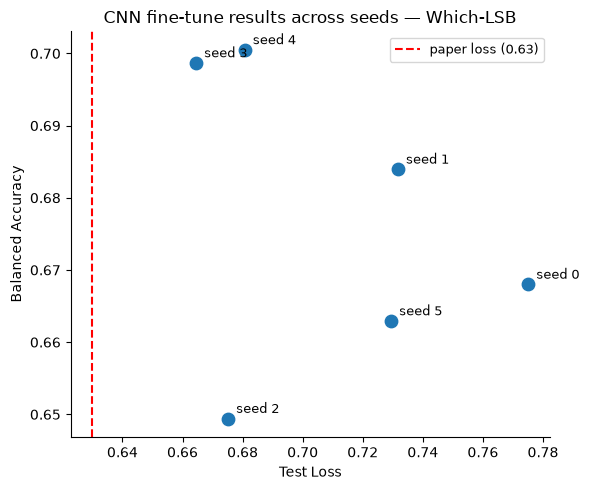

In [5]:
import matplotlib.pyplot as plt

seeds    = [0,        1,        2,        3,        4,        5       ]
loss     = [0.775018, 0.731640, 0.675107, 0.664455, 0.680649, 0.729365]
bal_acc  = [0.668013, 0.683957, 0.649426, 0.698691, 0.700508, 0.662947]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(loss, bal_acc, s=80, zorder=3)

for s, x, y in zip(seeds, loss, bal_acc):
    ax.annotate(f"seed {s}", (x, y), textcoords="offset points", xytext=(6, 4), fontsize=9)

ax.axvline(0.63, color="red", linestyle="--", linewidth=1.5, label="paper loss (0.63)")

ax.set_xlabel("Test Loss")
ax.set_ylabel("Balanced Accuracy")
ax.set_title("CNN fine-tune results across seeds — Which-LSB")
ax.legend(fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("seeds_plot_whichlsb.png", dpi=150)
plt.show()


In [1]:
import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, log_loss, confusion_matrix, classification_report

class_names = ['arm', 'stream', 'shell', 'diffuse']
prob_cols   = ['class_0', 'class_1', 'class_2', 'class_3']

test_df = load_dataset("mwalmsley/which-lsb")['test'].to_pandas()[['id_str', 'label']]


root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
folders = sorted([
    f for f in glob.glob(f"{root}/*which-lsb*2026-06-30*")
    if os.path.exists(os.path.join(f, "predictions_test.csv"))
    and os.path.exists(os.path.join(f, "checkpoints"))
])

print(f"Found {len(folders)} folders (should be 6):")
for f in folders:
    print("  ", os.path.basename(f))
print()

rows = []
for f in folders:
    pred = pd.read_csv(os.path.join(f, "predictions_test.csv"))
    m = pred.merge(test_df, on='id_str', how='inner')
    probs = m[prob_cols].values
    true  = m['label'].values
    pred_class = probs.argmax(axis=1)
    seed = os.path.basename(f).split('_')[-3]
    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, probs, labels=[0,1,2,3]),
        'balanced_acc': balanced_accuracy_score(true, pred_class),
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\n=== which-lsb 50% data ===")
print(f"Test loss:    {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}")
print(f"Balanced acc: {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")
print(f"\n(full-data 100% was: loss 0.7094±0.043, bal_acc 0.6773±0.021)")

# per-class detail on last seed — watch shell (the rare class that may collapse at 50%)
print("\n--- per-class detail (last seed) ---")
print(confusion_matrix(true, pred_class, labels=[0,1,2,3]))
print(classification_report(true, pred_class, target_names=class_names, zero_division=0))

/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Found 6 folders (should be 6):
   local_which-lsb_0_2026-06-30_19-56-09
   local_which-lsb_1_2026-06-30_19-58-26
   local_which-lsb_2_2026-06-30_20-02-00
   local_which-lsb_3_2026-06-30_20-04-43
   local_which-lsb_4_2026-06-30_20-07-42
   local_which-lsb_5_2026-06-30_20-10-07

seed  test_loss  balanced_acc  n_matched
   0   0.833054      0.432361        218
   1   0.820027      0.627556        218
   2   0.691240      0.537017        218
   3   0.735296      0.494706        218
   4   0.770049      0.463782        218
   5   0.765274      0.439815        218

=== which-lsb 50% data ===
Test loss:    0.7692 ± 0.0527
Balanced acc: 0.4992 ± 0.0737

(full-data 100% was: loss 0.7094±0.043, bal_acc 0.6773±0.021)

--- per-class detail (last seed) ---
[[57  4  0 12]
 [ 9  4  0 30]
 [ 0  0  0  6]
 [11  0  0 85]]
              precision    recall  f1-score   support

         arm       0.74      0.78      0.76        73
      stream       0.50      0.09      0.16        43
       shell       0.0

/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make 

In [19]:
import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, log_loss, recall_score, confusion_matrix

class_names = ['arm', 'stream', 'shell', 'diffuse']
prob_cols   = ['class_0', 'class_1', 'class_2', 'class_3']

test_df = load_dataset("mwalmsley/which-lsb")['test'].to_pandas()[['id_str', 'label']]

# the 25% runs 
root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
folders = sorted([
    f for f in glob.glob(f"{root}/*which-lsb_div4*")
    if os.path.exists(os.path.join(f, "predictions_test.csv"))
    and os.path.exists(os.path.join(f, "checkpoints"))
])

print(f"Found {len(folders)} folders (should be 6):")
for f in folders:
    print("  ", os.path.basename(f))
print()

rows = []
for f in folders:
    pred = pd.read_csv(os.path.join(f, "predictions_test.csv"))
    m = pred.merge(test_df, on='id_str', how='inner')
    probs = m[prob_cols].values
    true  = m['label'].values
    pred_class = probs.argmax(axis=1)
    seed = os.path.basename(f).split('_')[-3]

    
    per_class_recall = recall_score(true, pred_class, labels=[0,1,2,3], average=None, zero_division=0)

    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, probs, labels=[0,1,2,3]),
        'balanced_acc': balanced_accuracy_score(true, pred_class),
        'arm_rec':     per_class_recall[0],
        'stream_rec':  per_class_recall[1],
        'shell_rec':   per_class_recall[2],
        'diffuse_rec': per_class_recall[3],
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
pd.set_option('display.width', 200)
print(df.to_string(index=False))
print(f"\n=== which-lsb 25% data (div4, batch 8) ===")
print(f"Test loss:    {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}")
print(f"Balanced acc: {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")
print(f"\nPer-class recall (mean ± std) — the rare-class collapse story:")
for cls in ['arm','stream','shell','diffuse']:
    col = f'{cls}_rec'
    print(f"  {cls:8s}: {df[col].mean():.3f} ± {df[col].std():.3f}")
print(f"\n(compare — 100%: bal_acc 0.677 | 50%: [your number])")

Found 6 folders (should be 6):
   local_which-lsb_div4_0_2026-06-30_22-19-01
   local_which-lsb_div4_1_2026-06-30_22-20-31
   local_which-lsb_div4_2_2026-06-30_22-22-54
   local_which-lsb_div4_3_2026-06-30_22-24-26
   local_which-lsb_div4_4_2026-06-30_22-25-54
   local_which-lsb_div4_5_2026-06-30_22-27-54

seed  test_loss  balanced_acc  arm_rec  stream_rec  shell_rec  diffuse_rec  n_matched
   0   0.799548      0.473879 0.767123    0.232558   0.000000     0.895833        218
   1   1.102406      0.564163 0.561644    0.372093   0.500000     0.822917        218
   2   0.814809      0.551965 0.726027    0.325581   0.333333     0.822917        218
   3   0.774835      0.562272 0.780822    0.395349   0.333333     0.739583        218
   4   0.768645      0.686490 0.808219    0.302326   0.833333     0.802083        218
   5   0.797036      0.493677 0.739726    0.255814   0.166667     0.812500        218

=== which-lsb 25% data (div4, batch 8) ===
Test loss:    0.8429 ± 0.1283
Balanced acc: 0.

/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make 

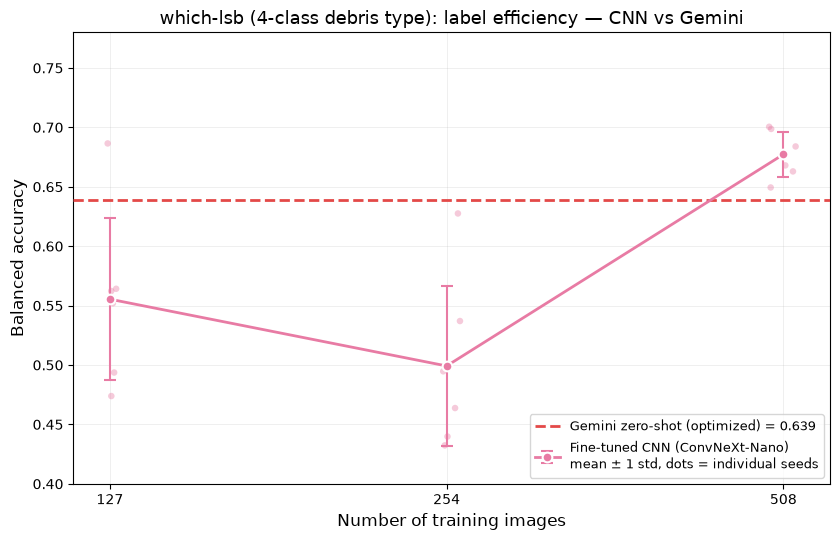

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

np.random.seed(0)

runs = {
    508: [0.668013, 0.683957, 0.649426, 0.698691, 0.700508, 0.662947],  # 100%
    254: [0.432361, 0.627556, 0.537017, 0.494706, 0.463782, 0.439815],  # 50% (div2, batch32)
    127: [0.473879, 0.564163, 0.551965, 0.562272, 0.686490, 0.493677],  # 25% (div4, batch8)
}
gemini = 0.639  # optimized zero-shot baseline

xs    = sorted(runs.keys())
means = [np.mean(runs[x]) for x in xs]
stds  = [np.std(runs[x])  for x in xs]

fig, ax = plt.subplots(figsize=(8.5, 5.5))

# individual seed dots (faint, jittered)
for x in xs:
    seeds = runs[x]
    jitter = x * np.random.uniform(-0.03, 0.03, size=len(seeds))
    ax.scatter(np.full(len(seeds), x) + jitter, seeds,
               s=22, color='#e87ba4', alpha=0.4, zorder=2, edgecolors='none')

# mean line + error bars
ax.errorbar(xs, means, yerr=stds, fmt='o-', color='#e87ba4',
            ecolor='#e87ba4', elinewidth=1.5, capsize=4,
            markersize=7, markerfacecolor='#e87ba4',
            markeredgecolor='white', markeredgewidth=1.5,
            linewidth=2, label='Fine-tuned CNN (ConvNeXt-Nano)\nmean ± 1 std, dots = individual seeds',
            zorder=4)

# Gemini baseline
ax.axhline(gemini, color='#e34948', linestyle='--', linewidth=2,
           label=f'Gemini zero-shot (optimized) = {gemini:.3f}', zorder=3)

ax.set_xscale('log')
ax.set_xlabel('Number of training images', fontsize=12)
ax.set_ylabel('Balanced accuracy', fontsize=12)
ax.set_title('which-lsb (4-class debris type): label efficiency — CNN vs Gemini', fontsize=13)

ax.set_xticks(xs)
ax.set_xticklabels([str(x) for x in xs])
ax.minorticks_off()
ax.set_ylim(0.40, 0.78)

ax.grid(True, which='major', linestyle='-', linewidth=0.4, alpha=0.35)
ax.legend(loc='lower right', fontsize=9, frameon=True)

plt.tight_layout()
plt.savefig('which_lsb_label_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

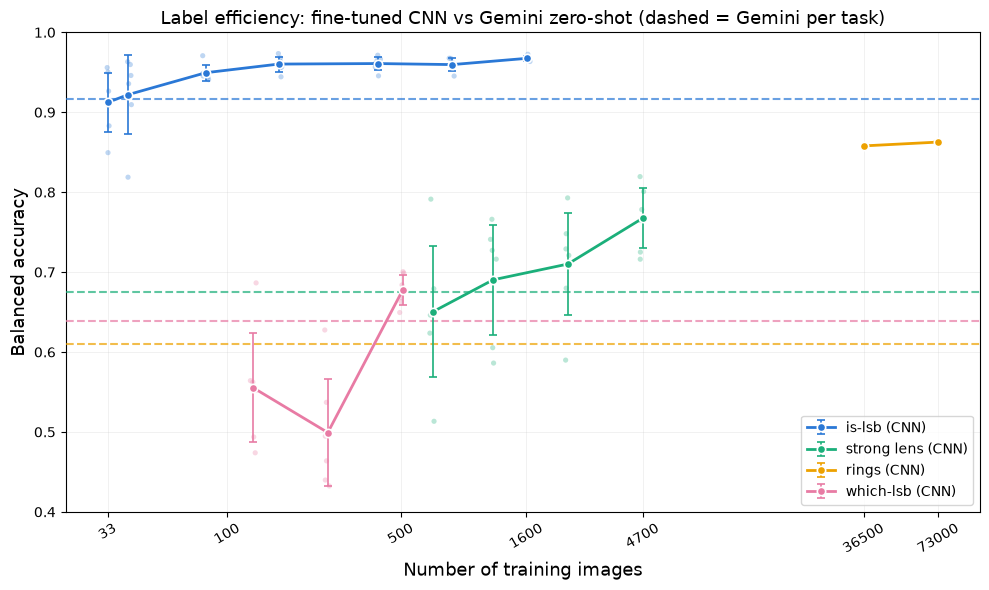

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

np.random.seed(0)

# --- per-seed balanced accuracies, keyed by n training images ---
tasks = {
    'is-lsb': {
        'color': '#2a78d6',
        'gemini': 0.917,
        'runs': {
            1612: [0.972541,0.969018,0.963544,0.967067,0.966345,0.966472],
            806:  [0.967321,0.945296,0.955650,0.961846,0.967575,0.960148],
            403:  [0.960870,0.945550,0.956626,0.966472,0.971351,0.964774],
            161:  [0.963457,0.944320,0.956626,0.955904,0.973430,0.967956],
            82:   [0.947502,0.940797,0.948818,0.945423,0.970756,0.943725],
            40:   [0.818748,0.946018,0.909521,0.963203,0.959681,0.935704],
            33:   [0.849429,0.882998,0.908799,0.950302,0.955904,0.926453],
        },
    },
    'strong lens': {
        'color': '#1baf7a',
        'gemini': 0.675,
        'runs': {
            4702: [0.725008,0.819480,0.800768,0.716122,0.764563,0.778257],
            2351: [0.729017,0.589888,0.720930,0.748024,0.792821,0.679847],
            1176: [0.766077,0.727195,0.586174,0.605405,0.716192,0.740959],
            672:  [0.513330,0.623612,0.679188,0.648085,0.791279,0.646193],
        },
    },
    'rings': {
        'color': '#eda100',
        'gemini': 0.61,
        'runs': {
            73000: [0.8627],           # full data (1 seed, ConvNeXt-Base)
            36500: [0.8579],           # 50% (1 seed, nano)
        },
    },
    'which-lsb': {
        'color': '#e87ba4',
        'gemini': 0.639,
        'runs': {
            508: [0.668013,0.683957,0.649426,0.698691,0.700508,0.662947],
            254: [0.432361,0.627556,0.537017,0.494706,0.463782,0.439815],
            127: [0.473879,0.564163,0.551965,0.562272,0.686490,0.493677],
        },
    },
}

fig, ax = plt.subplots(figsize=(10, 6))

for name, t in tasks.items():
    xs    = sorted(t['runs'].keys())
    means = [np.mean(t['runs'][x]) for x in xs]
    stds  = [np.std(t['runs'][x])  for x in xs]

    # seed dots
    for x in xs:
        seeds = t['runs'][x]
        jitter = x * np.random.uniform(-0.03, 0.03, size=len(seeds))
        ax.scatter(np.full(len(seeds), x)+jitter, seeds, s=14,
                   color=t['color'], alpha=0.3, zorder=2, edgecolors='none')

    # mean line + error bars
    ax.errorbar(xs, means, yerr=stds, fmt='o-', color=t['color'],
                ecolor=t['color'], elinewidth=1.2, capsize=3,
                markersize=6, markerfacecolor=t['color'],
                markeredgecolor='white', markeredgewidth=1.2,
                linewidth=2, label=f'{name} (CNN)', zorder=4)

    # matching Gemini baseline
    ax.axhline(t['gemini'], color=t['color'], linestyle='--',
               linewidth=1.5, alpha=0.7, zorder=3)

ax.set_xscale('log')
ax.set_xlabel('Number of training images', fontsize=13)
ax.set_ylabel('Balanced accuracy', fontsize=13)
ax.set_title('Label efficiency: fine-tuned CNN vs Gemini zero-shot (dashed = Gemini per task)',
             fontsize=13)

ax.set_xticks([33, 100, 500, 1600, 4700, 36500, 73000])
ax.get_xaxis().set_major_formatter(mticker.ScalarFormatter())
ax.minorticks_off()
plt.setp(ax.get_xticklabels(), rotation=30)
ax.set_ylim(0.40, 1.0)

ax.grid(True, which='major', linestyle='-', linewidth=0.4, alpha=0.3)
ax.legend(loc='lower right', fontsize=10, frameon=True)

plt.tight_layout()
plt.savefig('all_tasks_label_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

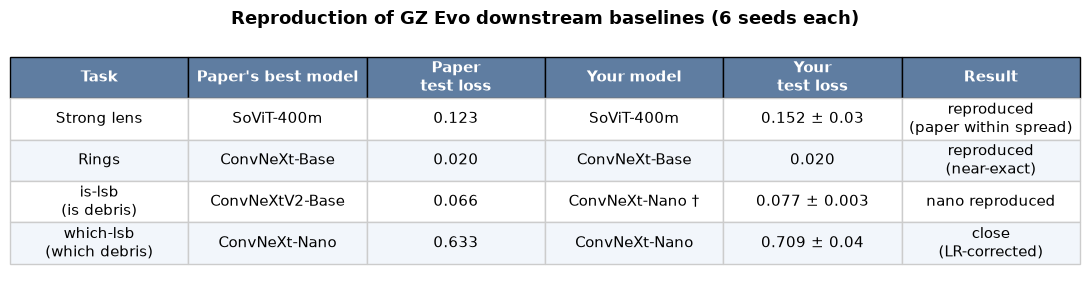

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 3))
ax.axis('off')

col_labels = ['Task', "Paper's best model", 'Paper\ntest loss', 'model used', 'Your\ntest loss', 'Result']

rows = [
    ['Strong lens',      'SoViT-400m',       '0.123', 'SoViT-400m',       '0.152 ± 0.03', 'reproduced\n(paper within spread)'],
    ['Rings',            'ConvNeXt-Base',    '0.020', 'ConvNeXt-Base',    '0.020',        'reproduced\n(near-exact)'],
    ['is-lsb\n(is debris)',   'ConvNeXtV2-Base',  '0.066', 'ConvNeXt-Nano †', '0.077 ± 0.003', 'nano reproduced'],
    ['which-lsb\n(which debris)', 'ConvNeXt-Nano', '0.633', 'ConvNeXt-Nano',   '0.709 ± 0.04', 'close\n(LR-corrected)'],
]

table = ax.table(cellText=rows, colLabels=col_labels,
                 cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.4)

# style header
for j in range(len(col_labels)):
    c = table[0, j]
    c.set_facecolor("#5f7da1")
    c.set_text_props(color='white', fontweight='bold')

# light zebra striping
for i in range(1, len(rows)+1):
    for j in range(len(col_labels)):
        if i % 2 == 0:
            table[i, j].set_facecolor('#f2f6fb')
        table[i, j].set_edgecolor('#cccccc')



plt.title('Reproduction of GZ Evo downstream baselines (6 seeds each)',
          fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('reproduction_table.png', dpi=150, bbox_inches='tight')
plt.show()

In [1]:
#lens

In [3]:
from datasets import load_dataset
ds = load_dataset("mwalmsley/euclid_strong_lens_expert_judges","classification")
print(ds['test'].features)        # shows the label class names + order
print(ds['test'].to_pandas()['label'].value_counts())   # confirm ~6.7% positive

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['not_grade_a_or_b_lens', 'grade_a_or_b_lens']), 'id_str': Value('string')}
label
0    1372
1     104
Name: count, dtype: int64


In [ ]:
# 100% 5880 
import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, recall_score, log_loss

# ground truth (load once)
test_df = load_dataset("mwalmsley/euclid_strong_lens_expert_judges", "classification")['test'].to_pandas()[['id_str','label']]

# find all strong-lens run folders
root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
folders = sorted(glob.glob(f"{root}/*euclid_strong_lens*"))

rows = []
for f in folders:
    csv = os.path.join(f, "predictions_test.csv")
    if not os.path.exists(csv):
        print(f"SKIP (no predictions): {os.path.basename(f)}")
        continue
    pred = pd.read_csv(csv)
    m = pred.merge(test_df, on='id_str', how='inner')
    prob = m['class_1'].values
    true = m['label'].values
    pclass = (prob >= 0.5).astype(int)

    # extract seed from folder name (..._<seed>_<timestamp>)
    seed = os.path.basename(f).split('_')[-3]   # adjust if parsing is off

    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, prob),
        'balanced_acc': balanced_accuracy_score(true, pclass),
        'lens_recall': recall_score(true, pclass, pos_label=1),
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\nTest loss:     {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}")
print(f"Balanced acc:  {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")
print(f"Lens recall:   {df['lens_recall'].mean():.4f} ± {df['lens_recall'].std():.4f}")

/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed  test_loss  balanced_acc  lens_recall  n_matched
   0   0.162965      0.725008     0.471154       1476
   1   0.200329      0.819480     0.682692       1476
   2   0.114103      0.800768     0.615385       1476
   3   0.153236      0.716122     0.451923       1476
  42   0.139104      0.764563     0.548077       1476
   4   0.141248      0.778257     0.576923       1476

Test loss:     0.1518 ± 0.0289
Balanced acc:  0.7674 ± 0.0409
Lens recall:   0.5577 ± 0.0873


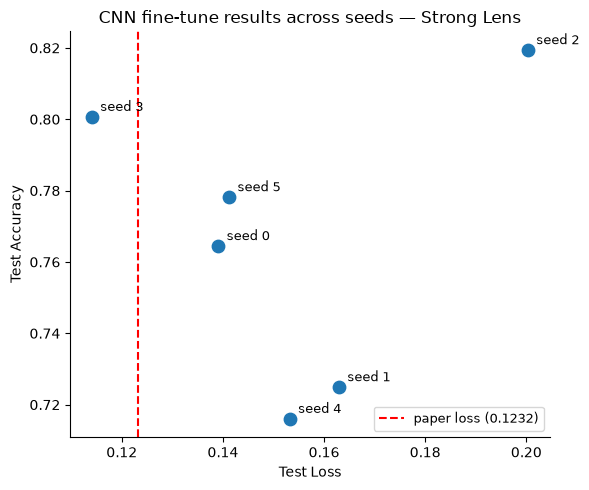

In [6]:
import matplotlib.pyplot as plt

seeds  = [1,        2,        3,        4,        0,        5       ]
loss   = [0.162965, 0.200329, 0.114103, 0.153236, 0.139104, 0.141248]
acc    = [0.725008, 0.819480, 0.800768, 0.716122, 0.764563, 0.778257]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(loss, acc, s=80, zorder=3)

for s, x, y in zip(seeds, loss, acc):
    ax.annotate(f"seed {s}", (x, y), textcoords="offset points", xytext=(6, 4), fontsize=9)

ax.axvline(0.1232, color="red", linestyle="--", linewidth=1.5, label="paper loss (0.1232)")

ax.set_xlabel("Test Loss")
ax.set_ylabel("Test Accuracy")
ax.set_title("CNN fine-tune results across seeds — Strong Lens")
ax.legend(fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("seeds_plot_stronglens.png", dpi=150)
plt.show()



In [ ]:

import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, recall_score, log_loss

# ground truth
test_df = load_dataset("mwalmsley/euclid_strong_lens_expert_judges", "classification")['test'].to_pandas()[['id_str','label']]

# find the 50%-data 
root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
folders = sorted([
    f for f in glob.glob(f"{root}/*euclid_strong_lens*2026-06-27*")
    if os.path.exists(os.path.join(f, "predictions_test.csv"))
    and os.path.exists(os.path.join(f, "checkpoints"))
])

print(f"Found {len(folders)} folders (should be 6):")
for f in folders:
    print("  ", os.path.basename(f))
print()

rows = []
for f in folders:
    pred = pd.read_csv(os.path.join(f, "predictions_test.csv"))
    m = pred.merge(test_df, on='id_str', how='inner')
    prob = m['class_1'].values
    true = m['label'].values
    pclass = (prob >= 0.5).astype(int)
    seed = os.path.basename(f).split('_')[-3]
    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, prob),
        'balanced_acc': balanced_accuracy_score(true, pclass),
        'lens_recall': recall_score(true, pclass, pos_label=1),
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\n=== 50% data (divisor=2) ===")
print(f"Test loss:    {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}")
print(f"Balanced acc: {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")
print(f"Lens recall:  {df['lens_recall'].mean():.4f} ± {df['lens_recall'].std():.4f}")


Found 6 folders (should be 6):
   local_euclid_strong_lens_expert_judges_0_2026-06-27_13-55-39
   local_euclid_strong_lens_expert_judges_1_2026-06-27_15-30-41
   local_euclid_strong_lens_expert_judges_2_2026-06-27_16-33-39
   local_euclid_strong_lens_expert_judges_3_2026-06-27_17-43-05
   local_euclid_strong_lens_expert_judges_4_2026-06-27_18-46-04
   local_euclid_strong_lens_expert_judges_5_2026-06-27_21-05-20

seed  test_loss  balanced_acc  lens_recall  n_matched
   0   0.182770      0.729017     0.471154       1476
   1   0.173811      0.589888     0.182692       1476
   2   0.145421      0.720930     0.461538       1476
   3   0.177646      0.748024     0.528846       1476
   4   0.163927      0.792821     0.625000       1476
   5   0.242769      0.679847     0.375000       1476

=== 50% data (divisor=2) ===
Test loss:    0.1811 ± 0.0330
Balanced acc: 0.7101 ± 0.0695
Lens recall:  0.4407 ± 0.1510

(full-data 100% was: loss 0.152±0.029, bal_acc 0.767±0.041, recall 0.558±0.087)


In [ ]:

import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, recall_score, log_loss

# ground truth
test_df = load_dataset("mwalmsley/euclid_strong_lens_expert_judges", "classification")['test'].to_pandas()[['id_str','label']]

# find the 25%-data 
root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
folders = sorted([
    f for f in glob.glob(f"{root}/*euclid_strong_lens*2026-06-28*")
    if os.path.exists(os.path.join(f, "predictions_test.csv"))
    and os.path.exists(os.path.join(f, "checkpoints"))
])

print(f"Found {len(folders)} folders (should be 6):")
for f in folders:
    print("  ", os.path.basename(f))
print()

rows = []
for f in folders:
    pred = pd.read_csv(os.path.join(f, "predictions_test.csv"))
    m = pred.merge(test_df, on='id_str', how='inner')
    prob = m['class_1'].values
    true = m['label'].values
    pclass = (prob >= 0.5).astype(int)
    seed = os.path.basename(f).split('_')[-3]
    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, prob),
        'balanced_acc': balanced_accuracy_score(true, pclass),
        'lens_recall': recall_score(true, pclass, pos_label=1),
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\n=== 25% data (divisor=4) ===")
print(f"Test loss:    {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}")
print(f"Balanced acc: {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")
print(f"Lens recall:  {df['lens_recall'].mean():.4f} ± {df['lens_recall'].std():.4f}")


/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Found 6 folders (should be 6):
   local_euclid_strong_lens_expert_judges_0_2026-06-28_12-57-12
   local_euclid_strong_lens_expert_judges_1_2026-06-28_13-50-30
   local_euclid_strong_lens_expert_judges_2_2026-06-28_14-46-25
   local_euclid_strong_lens_expert_judges_3_2026-06-28_15-26-02
   local_euclid_strong_lens_expert_judges_4_2026-06-28_16-05-37
   local_euclid_strong_lens_expert_judges_5_2026-06-28_16-51-49

seed  test_loss  balanced_acc  lens_recall  n_matched
   0   0.217886      0.766077     0.605769       1476
   1   0.163609      0.727195     0.471154       1476
   2   0.193973      0.586174     0.173077       1476
   3   0.224240      0.605405     0.211538       1476
   4   0.211869      0.716192     0.461538       1476
   5   0.222232      0.740959     0.509615       1476

=== 25% data (divisor=4) ===
Test loss:    0.2056 ± 0.0233
Balanced acc: 0.6903 ± 0.0754
Lens recall:  0.4054 ± 0.1732


In [ ]:

import pandas as pd
import numpy as np
import glob, os
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score, recall_score, log_loss

# ground truth
test_df = load_dataset("mwalmsley/euclid_strong_lens_expert_judges", "classification")['test'].to_pandas()[['id_str','label']]

# find the 15%-data 
root = "/geir_data/scr/reem/gz_evo_results/dnb_debug"
folders = sorted([
    f for f in glob.glob(f"{root}/*euclid_strong_lens*2026-06-30*")
    if os.path.exists(os.path.join(f, "predictions_test.csv"))
    and os.path.exists(os.path.join(f, "checkpoints"))
])

print(f"Found {len(folders)} folders (should be 6):")
for f in folders:
    print("  ", os.path.basename(f))
print()

rows = []
for f in folders:
    pred = pd.read_csv(os.path.join(f, "predictions_test.csv"))
    m = pred.merge(test_df, on='id_str', how='inner')
    prob = m['class_1'].values
    true = m['label'].values
    pclass = (prob >= 0.5).astype(int)
    seed = os.path.basename(f).split('_')[-3]
    rows.append({
        'seed': seed,
        'test_loss': log_loss(true, prob),
        'balanced_acc': balanced_accuracy_score(true, pclass),
        'lens_recall': recall_score(true, pclass, pos_label=1),
        'n_matched': len(m),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\n=== 15% data (divisor=7) ===")
print(f"Test loss:    {df['test_loss'].mean():.4f} ± {df['test_loss'].std():.4f}")
print(f"Balanced acc: {df['balanced_acc'].mean():.4f} ± {df['balanced_acc'].std():.4f}")
print(f"Lens recall:  {df['lens_recall'].mean():.4f} ± {df['lens_recall'].std():.4f}")


/home/reem/local/miniconda3/envs/astro1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Found 6 folders (should be 6):
   local_euclid_strong_lens_expert_judges_0_2026-06-30_16-10-48
   local_euclid_strong_lens_expert_judges_1_2026-06-30_16-37-03
   local_euclid_strong_lens_expert_judges_2_2026-06-30_16-59-31
   local_euclid_strong_lens_expert_judges_3_2026-06-30_17-23-52
   local_euclid_strong_lens_expert_judges_4_2026-06-30_17-46-21
   local_euclid_strong_lens_expert_judges_5_2026-06-30_18-21-47

seed  test_loss  balanced_acc  lens_recall  n_matched
   0   0.539895      0.513330     0.028846       1476
   1   0.207284      0.623612     0.259615       1476
   2   0.268324      0.679188     0.384615       1476
   3   0.272569      0.648085     0.317308       1476
   4   0.281755      0.791279     0.663462       1476
   5   0.241182      0.646193     0.307692       1476

=== 15% data (divisor=7) ===
Test loss:    0.3018 ± 0.1197
Balanced acc: 0.6503 ± 0.0897
Lens recall:  0.3269 ± 0.2051


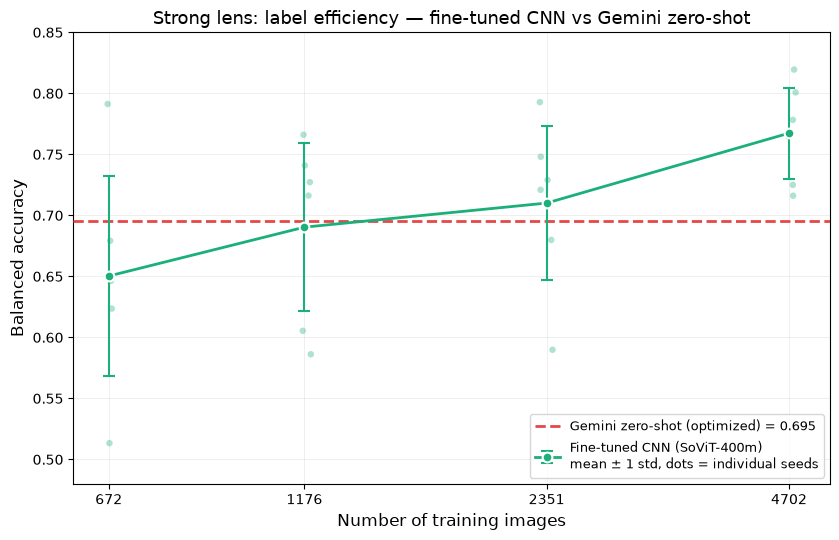

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

runs = {
    4702: [0.725008, 0.819480, 0.800768, 0.716122, 0.764563, 0.778257],
    2351: [0.729017, 0.589888, 0.720930, 0.748024, 0.792821, 0.679847],
    1176: [0.766077, 0.727195, 0.586174, 0.605405, 0.716192, 0.740959],
    672:  [0.513330, 0.623612, 0.679188, 0.648085, 0.791279, 0.646193],
}
gemini = 0.73

xs    = sorted(runs.keys())
means = [np.mean(runs[x]) for x in xs]
stds  = [np.std(runs[x])  for x in xs]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
np.random.seed(0)

for x in xs:
    seeds = runs[x]
    jitter = x * np.random.uniform(-0.02, 0.02, size=len(seeds))
    ax.scatter(np.full(len(seeds), x) + jitter, seeds,
               s=22, color='#1baf7a', alpha=0.35, zorder=2, edgecolors='none')

ax.errorbar(xs, means, yerr=stds, fmt='o-', color='#1baf7a',
            ecolor='#1baf7a', elinewidth=1.5, capsize=4,
            markersize=7, markerfacecolor='#1baf7a',
            markeredgecolor='white', markeredgewidth=1.5,
            linewidth=2, label='Fine-tuned CNN (SoViT-400m)\nmean ± 1 std, dots = individual seeds',
            zorder=4)

ax.axhline(gemini, color='#e34948', linestyle='--', linewidth=2,
           label=f'Gemini zero-shot (optimized) = {gemini:.3f}', zorder=3)

ax.set_xscale('log')
ax.set_xlabel('Number of training images', fontsize=12)
ax.set_ylabel('Balanced accuracy', fontsize=12)
ax.set_title('Strong lens: label efficiency — fine-tuned CNN vs Gemini zero-shot', fontsize=13)

ax.set_xticks(xs)
ax.set_xticklabels([str(x) for x in xs])
ax.minorticks_off()
ax.set_ylim(0.48, 0.85)

ax.grid(True, which='major', linestyle='-', linewidth=0.4, alpha=0.35)
ax.legend(loc='lower right', fontsize=9, frameon=True)   # inside, top-right

plt.tight_layout()
plt.savefig('strong_lens_label_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()